# Лабораторна робота № 2

## Оптимізаційна задача та аналіз чутливості

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Побудувати оптимізаційну модель у двох середовищах, прочитати звіт про стійкість
і **ухвалити на його основі господарське рішення**.

Розв'язати задачу — не мета. Solver зробить це за дві секунди. Робота оцінюється за
те, що ви зумієте зі звіту витягнути.

### Дві частини

| Частина | Задача | Де виконується |
|---|---|---|
| **1** | виробнича задача — Excel і Python | аудиторно |
| **2** | транспортна задача — Python | самостійно |

Друга частина потрібна не для повторення. Там та сама методика поводиться інакше,
і ви маєте побачити, де саме проходить межа її застосовності.

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Виконується згори донизу на чистому
   ядрі** (Kernel → Restart & Run All) без помилок — перевіряється першою дією на захисті.
2. Файл Excel з моделлю, налаштуваннями Solver і **звітом про стійкість** окремим аркушем.
3. Заповнена декларація про використання ШІ (етап 12).

### Оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Модель не сформульовано або розв'язок не отримано |
| 1 | Розв'язок отримано лише в одному середовищі, звіт про стійкість не проаналізовано |
| 2 | Задачу розв'язано в обох середовищах і звіти зіставлено, але тіньові ціни та діапазони не інтерпретовано |
| 4 | Звіт прочитано й перевірено експериментом, ухвалено обґрунтоване рішення про закупівлю, виконано частину 2 з поясненням розбіжності |

---
## Крок 0. Ваші дані та варіант

In [1]:
ПІБ = 'Климишин Данило Ігорович'        # напр. 'Шевченко Тарас'
ГРУПА = 'ШІ-31'      # напр. 'КН-31'
ВАРІАНТ = 8     # ваш номер за списком групи

assert ПІБ and ГРУПА and 1 <= ВАРІАНТ <= 30, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ (1..30)'

In [2]:
# --- клітинку не редагувати: вона видає дані вашого варіанта -----------------
import json, numpy as np, pandas as pd

ДАНІ_ВАРІАНТІВ = json.loads('''{"1": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[0, 2, 1, 1], [3, 3, 0, 6], [2, 3, 0, 2], [4, 6, 0, 5], [3, 1, 5, 4]], "c": [21, 69, 44, 39], "b": [929, 410, 507, 865, 425], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.2, "обсяг_пропозиції": 44}, "2": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 2, 5, 2], [6, 5, 4, 2], [5, 2, 0, 3], [2, 1, 5, 0], [5, 5, 6, 2]], "c": [40, 66, 24, 34], "b": [1271, 702, 915, 1388, 804], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.7, "обсяг_пропозиції": 204}, "3": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 2, 6, 6], [3, 4, 3, 6], [1, 6, 6, 0], [3, 1, 6, 1], [4, 1, 1, 4]], "c": [51, 16, 34, 22], "b": [1189, 686, 1311, 512, 1030], "ресурс_пропозиції": 3, "ціна_пропозиції": 11.3, "обсяг_пропозиції": 348}, "4": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 0, 0, 0], [1, 0, 5, 2], [2, 4, 6, 5], [3, 0, 5, 3], [2, 1, 2, 5]], "c": [41, 50, 54, 26], "b": [815, 344, 840, 840, 382], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.3, "обсяг_пропозиції": 144}, "5": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 0, 6, 6], [3, 2, 2, 4], [5, 5, 0, 6], [2, 1, 5, 3], [5, 5, 4, 2]], "c": [32, 66, 25, 24], "b": [874, 1034, 1349, 845, 1394], "ресурс_пропозиції": 2, "ціна_пропозиції": 8.6, "обсяг_пропозиції": 90}, "6": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[3, 2, 1, 4], [4, 2, 2, 1], [3, 5, 1, 2], [3, 2, 0, 2], [6, 4, 6, 3]], "c": [40, 62, 19, 57], "b": [630, 391, 1349, 811, 1085], "ресурс_пропозиції": 1, "ціна_пропозиції": 29.5, "обсяг_пропозиції": 268}, "7": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[0, 0, 5, 5], [4, 4, 0, 1], [2, 4, 0, 6], [6, 3, 4, 1], [2, 2, 1, 0]], "c": [20, 59, 63, 41], "b": [1189, 1189, 1217, 915, 424], "ресурс_пропозиції": 3, "ціна_пропозиції": 8.0, "обсяг_пропозиції": 314}, "8": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[2, 1, 3, 5], [3, 1, 0, 6], [1, 6, 1, 5], [2, 2, 4, 0], [6, 1, 2, 2]], "c": [60, 25, 59, 25], "b": [1279, 761, 376, 1230, 1065], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.5, "обсяг_пропозиції": 234}, "9": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 2, 1, 2], [5, 0, 1, 3], [5, 4, 6, 4], [4, 1, 1, 5], [6, 0, 3, 0]], "c": [58, 39, 54, 16], "b": [1147, 1199, 1280, 404, 1170], "ресурс_пропозиції": 2, "ціна_пропозиції": 6.1, "обсяг_пропозиції": 672}, "10": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 0, 4, 3], [0, 6, 0, 6], [5, 5, 3, 5], [6, 2, 3, 3], [3, 0, 0, 4]], "c": [20, 29, 37, 63], "b": [905, 344, 866, 1390, 355], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.3, "обсяг_пропозиції": 78}, "11": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 3], [3, 1, 4, 0], [1, 0, 3, 2], [3, 2, 2, 6], [3, 6, 0, 3]], "c": [30, 16, 51, 35], "b": [1312, 838, 1062, 1038, 1236], "ресурс_пропозиції": 1, "ціна_пропозиції": 15.6, "обсяг_пропозиції": 778}, "12": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 2, 0, 5], [1, 1, 3, 6], [6, 3, 5, 4], [2, 4, 6, 0], [4, 6, 2, 4]], "c": [39, 55, 36, 26], "b": [788, 661, 458, 1005, 535], "ресурс_пропозиції": 4, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 762}, "13": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[1, 5, 3, 0], [6, 4, 6, 3], [4, 4, 4, 1], [0, 3, 5, 3], [3, 5, 3, 3]], "c": [59, 42, 53, 19], "b": [937, 1390, 603, 1120, 1334], "ресурс_пропозиції": 2, "ціна_пропозиції": 15.1, "обсяг_пропозиції": 646}, "14": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 3, 3, 4], [6, 6, 1, 6], [1, 3, 5, 1], [1, 5, 1, 4], [4, 4, 0, 3]], "c": [26, 56, 41, 40], "b": [969, 672, 1364, 878, 618], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 222}, "15": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 3, 3, 1], [2, 5, 6, 6], [3, 1, 0, 0], [0, 4, 4, 6], [2, 2, 2, 6]], "c": [64, 58, 34, 63], "b": [613, 316, 1035, 739, 810], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.4, "обсяг_пропозиції": 354}, "16": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[1, 6, 4, 2], [4, 1, 1, 2], [4, 4, 6, 6], [5, 6, 3, 3], [1, 2, 4, 2]], "c": [33, 40, 58, 17], "b": [412, 1005, 996, 599, 390], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.2, "обсяг_пропозиції": 44}, "17": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[2, 6, 0, 3], [2, 5, 5, 3], [6, 0, 4, 5], [1, 3, 6, 2], [0, 1, 4, 4]], "c": [33, 52, 20, 66], "b": [989, 1079, 873, 1327, 1224], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.9, "обсяг_пропозиції": 402}, "18": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 3, 0, 1], [0, 6, 1, 6], [1, 0, 4, 1], [2, 6, 3, 4], [3, 1, 6, 5]], "c": [66, 54, 18, 66], "b": [1217, 668, 923, 1040, 619], "ресурс_пропозиції": 4, "ціна_пропозиції": 34.9, "обсяг_пропозиції": 100}, "19": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 2], [3, 3, 4, 5], [2, 1, 0, 4], [4, 1, 5, 0], [0, 3, 6, 3]], "c": [67, 52, 41, 40], "b": [315, 617, 815, 423, 1193], "ресурс_пропозиції": 1, "ціна_пропозиції": 9.3, "обсяг_пропозиції": 332}, "20": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 4, 5, 1], [2, 0, 5, 4], [4, 0, 2, 3], [3, 3, 4, 3], [4, 4, 5, 2]], "c": [42, 63, 35, 56], "b": [1191, 331, 685, 1275, 971], "ресурс_пропозиції": 4, "ціна_пропозиції": 12.2, "обсяг_пропозиції": 604}, "21": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 3, 6], [4, 4, 3, 2], [4, 4, 4, 0], [1, 1, 5, 3], [0, 2, 6, 5]], "c": [32, 66, 26, 64], "b": [464, 393, 354, 597, 887], "ресурс_пропозиції": 0, "ціна_пропозиції": 9.4, "обсяг_пропозиції": 190}, "22": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[6, 0, 2, 6], [3, 4, 0, 4], [4, 3, 1, 5], [5, 5, 6, 2], [2, 0, 1, 5]], "c": [65, 36, 50, 63], "b": [891, 1247, 613, 1070, 1259], "ресурс_пропозиції": 2, "ціна_пропозиції": 13.6, "обсяг_пропозиції": 64}, "23": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[1, 2, 4, 6], [4, 6, 2, 5], [0, 5, 3, 1], [0, 0, 5, 1], [5, 4, 0, 5]], "c": [15, 35, 49, 23], "b": [1251, 637, 304, 629, 923], "ресурс_пропозиції": 2, "ціна_пропозиції": 10.9, "обсяг_пропозиції": 146}, "24": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[3, 2, 6, 1], [0, 2, 5, 6], [2, 4, 4, 0], [5, 6, 2, 5], [2, 4, 2, 1]], "c": [45, 61, 59, 38], "b": [927, 1384, 1294, 798, 323], "ресурс_пропозиції": 4, "ціна_пропозиції": 20.5, "обсяг_пропозиції": 110}, "25": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 4, 4], [2, 1, 4, 1], [3, 1, 4, 4], [1, 4, 2, 0], [6, 4, 6, 6]], "c": [35, 27, 63, 61], "b": [1399, 843, 308, 1393, 713], "ресурс_пропозиції": 2, "ціна_пропозиції": 7.7, "обсяг_пропозиції": 334}, "26": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 1, 4, 4], [3, 1, 5, 0], [6, 3, 6, 3], [1, 3, 6, 1], [6, 4, 5, 2]], "c": [46, 57, 60, 39], "b": [513, 1330, 796, 406, 1258], "ресурс_пропозиції": 3, "ціна_пропозиції": 18.1, "обсяг_пропозиції": 448}, "27": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 6, 0], [6, 5, 6, 0], [5, 2, 3, 0], [6, 4, 3, 6], [6, 0, 0, 3]], "c": [24, 61, 50, 57], "b": [1179, 1358, 417, 463, 610], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.0, "обсяг_пропозиції": 742}, "28": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[4, 5, 6, 2], [6, 4, 2, 1], [0, 5, 4, 3], [6, 6, 3, 3], [4, 4, 4, 1]], "c": [37, 41, 30, 29], "b": [514, 461, 378, 834, 488], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.5, "обсяг_пропозиції": 174}, "29": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 5, 0, 5], [6, 0, 6, 1], [5, 2, 2, 3], [0, 3, 0, 1], [4, 5, 5, 0]], "c": [33, 57, 58, 62], "b": [820, 523, 670, 977, 1074], "ресурс_пропозиції": 0, "ціна_пропозиції": 15.2, "обсяг_пропозиції": 570}, "30": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 1, 4, 0], [6, 5, 1, 4], [5, 6, 1, 4], [1, 2, 6, 0], [1, 0, 3, 1]], "c": [51, 44, 69, 55], "b": [379, 620, 1256, 502, 414], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.9, "обсяг_пропозиції": 230}}''')

V = ДАНІ_ВАРІАНТІВ[str(ВАРІАНТ)]
A = np.array(V['A'], float)          # витрати ресурсу i на один виріб j
c = np.array(V['c'], float)          # прибуток з одного виробу
b = np.array(V['b'], float)          # запас ресурсу на плановий період
вироби, ресурси = V['вироби'], V['ресурси']

print('ВАРІАНТ %d · %s, %s, %s' % (ВАРІАНТ, ПІБ, ГРУПА, V['фірма']))
print('=' * 78)
print('Підприємство %s виготовляє %s. Одиниця виміру плану: %s.' % (V['фірма'], V['що'], V['од']))
print()
таб = pd.DataFrame(A, index=ресурси, columns=вироби).astype(int)
таб['ЗАПАС'] = b.astype(int)
print(таб.to_string())
print()
print(pd.DataFrame([c.astype(int)], index=['Прибуток з одиниці'], columns=вироби).to_string())
print()
print('ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)')
print('  ресурс: %s' % ресурси[V['ресурс_пропозиції']])
print('  ціна:   %.1f за одиницю' % V['ціна_пропозиції'])
print('  обсяг:  до %d одиниць' % V['обсяг_пропозиції'])

ВАРІАНТ 8 · Климишин Данило Ігорович, ШІ-31, «Друк-Сервіс»
Підприємство «Друк-Сервіс» виготовляє поліграфію. Одиниця виміру плану: тис. прим./тиждень.

                          Буклет  Каталог  Календар  Плакат  ЗАПАС
Крейдований папір, кг          2        1         3       5   1279
Офсетний папір, кг             3        1         0       6    761
Фарба, кг                      1        6         1       5    376
Друкарська машина, год         2        2         4       0   1230
Різка й фальцювання, год       6        1         2       2   1065

                    Буклет  Каталог  Календар  Плакат
Прибуток з одиниці      60       25        59      25

ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)
  ресурс: Друкарська машина, год
  ціна:   9.5 за одиницю
  обсяг:  до 234 одиниць


In [3]:
import matplotlib.pyplot as plt
try:
    import pulp
    ПУЛП = True
except ImportError:
    ПУЛП = False
    print('pulp не встановлено — скористайтеся scipy.optimize.linprog')
from scipy.optimize import linprog

pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

---
# ЧАСТИНА 1. Виробнича задача

# Етап 1. Формалізація

Перш ніж будувати таблицю, запишіть модель словами й формулами. Це найважливіші
двадцять хвилин роботи: помилку тут не виправить жодна кнопка.

### Завдання 1.1
Заповніть у клітинці нижче:

* **змінні рішення** — що саме ви обираєте і в яких одиницях;
* **цільова функція** — що робите найбільшим, з коефіцієнтами вашого варіанта;
* **обмеження** — по одному рядку на кожен ресурс, з числами вашого варіанта;
* **умови невід'ємності**.

Пишіть формулами, а не описом. Приклад запису одного обмеження:
`8·x1 + 4·x2 + 0·x3 + 2·x4 ≤ 1280   (конвеєр A)`

**Відповідь 1.1 — символічна модель**

Змінні рішення: 

        X1(обсяг виготовлення буклетів, тис. прим./тиждень)
        X2(обсяг виготовлення каталогів, тис. прим./тиждень)
        Х3(обсяг виготовлення календарів, тис. прим./тиждень)
        Х4(обсяг виготовлення плакатів, тис. прим./тиждень)

Цільова функція: 60 * X1 + 25 * X2 + 59 * X3 + 25 * X4 -> max

Обмеження: 

           2*X1 +   X2 + 3*X3 + 5*X4 <= 1279 (Крейдований папір, кг)
           3*X1 +   X2 +   0  + 6*X4 <= 761 (Офсетний папір, кг)
             X1 + 6*X2 +   X3 + 5*X4 <= 376 (Фарба, кг)
           2*X1 + 2*X2 + 4*X3 +   0  <= 1230 (Друкарська машина, год)
           6*X1 +   X2 + 2*X3 + 2*X4 <= 1065 (Різка й фальцювання, год)

Невід'ємність: X1, X2, X3, X4 >= 0


### Завдання 1.2 — питання на розуміння
Чому запас ресурсу — це **параметр**, а не змінна рішення? Що змінилося б у моделі,
якби підприємство могло докупити ресурс у будь-якій кількості?


**Відповідь 1.2:**

Запас ресурсу це параметр, а не змінна рішення, тому що задача ставиться так, що ресурси обмежені і відповідно їхня кількість не може змінюватись, тому це параметр.

Якби підприємство могло докуповувати ресурси в будь-якій кількості, обмеження на ресурси би змінювались і відповідно би змінювалась цільова функція, в ній би довелось віднімати витрати на закупівлю додаткових ресурсів. Модель би закуповувала додаткові ресурси тільки тоді, коли прибуток від додаткової одиниці ресурсу перевищував ціну закупівлі. Якщо закупівля дорожча за вигоду, обсяг закупівлі дорівнюватиме 0.

---
# Етап 2. Розв'язання в Excel

1. Побудуйте табличну модель: окремо клітинки змінних рішення, окремо витрати ресурсів,
   окремо цільова функція. Не змішуйте вхідні дані з формулами.
2. Налаштуйте **Пошук рішення (Solver)**: цільова клітинка на максимум, клітинки змінних,
   обмеження по кожному ресурсу, невід'ємність, метод «Симплекс-метод для лінійних задач».
3. Отримайте розв'язок і **обов'язково замовте «Звіт про стійкість»** окремим аркушем.

**Що подати:** файл Excel зі скріншотом налаштувань Solver, оптимальним планом і звітом.

### Завдання 2.1
Перенесіть результат Excel у клітинку нижче — його порівняємо з Python.

In [4]:
# впишіть числа, які дав Excel
EXCEL_ПЛАН    = [88.04, 0, 263.47, 4.89]     # оптимальний випуск кожного виробу
EXCEL_ПРИБУТОК = 20950.16667             # значення цільової функції

print('Excel:', EXCEL_ПЛАН, '| прибуток', EXCEL_ПРИБУТОК)

Excel: [88.04, 0, 263.47, 4.89] | прибуток 20950.16667


---
# Етап 3. Розв'язання в Python

### Завдання 3.1
Побудуйте ту саму модель у Python і розв'яжіть її. Можна `pulp`, можна
`scipy.optimize.linprog` — на ваш вибір.

*Очікуваний результат: оптимальний план і значення цільової функції.*

**Увага на знак.** `linprog` завжди мінімізує. Щоб максимізувати прибуток, передають
`-c`, а результат беруть як `-r.fun`.

In [5]:
# ВАШ КОД
import numpy as np
from scipy.optimize import linprog
c = np.array([-60, -25, -59, -25])

A_ub = np.array([
    [2, 1, 3, 5],  # Крейдований папір, кг
    [3, 1, 0, 6],  # Офсетний папір, кг
    [1, 6, 1, 5],  # Фарба, кг
    [2, 2, 4, 0],  # Друкарська машина, год
    [6, 1, 2, 2]   # Різка й фальцювання, год
])

b_ub = np.array([1279, 761, 376, 1230, 1065])

bounds = [(0, None), (0, None), (0, None), (0, None)]

res = linprog(
    c=c,
    A_ub=A_ub,
    b_ub=b_ub,
    bounds=bounds,
    method='highs'
)


план = res['x']
прибуток = -res['fun']


**Самоперевірка етапу 3.** Excel і Python мають дати той самий результат.

In [6]:
assert план is not None and прибуток is not None, 'спершу розв’яжіть задачу'
assert abs(прибуток - EXCEL_ПРИБУТОК) < 0.5, (
    'Excel дав %.2f, Python %.2f — знайдіть, де розбіжність' % (EXCEL_ПРИБУТОК, прибуток))
assert np.allclose(np.array(план, float), np.array(EXCEL_ПЛАН, float), atol=0.5), \
    'плани не збігаються — перевірте обмеження'
print('Етап 3 пройдено: обидва середовища дали однаковий результат')

Етап 3 пройдено: обидва середовища дали однаковий результат


---
# Етап 4. Читання звіту про стійкість

Звіт Excel має два блоки. Заповніть обидві таблиці — беріть числа зі **звіту**,
а не з власних обчислень.

### Завдання 4.1 — блок «Обмеження»

| Ресурс | Кінцеве значення | Тіньова ціна | Права частина | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Крейдований папір | 991 | 0 |1279 | 1E+030 | 288 |
| Офсетний папір | 293.5 | 0 | 761 | 1E+030  | 467.5 |
| Фарба | 376 | 2.66666666666667 | 376 | 288 | 23.5 |
| Друкарська машина | 1230 | 11.1666666666667 | 1230 | 117.5 | 903.357142857143 |
| Різка й фальцювання | 1065 | 5.83333333333333 | 1065 | 235 | 422.6 |

**Які ресурси в дефіциті, а які в надлишку? Як ви це визначили?**

    У дефіциті: Фарба, Друкарська машина(години), Різка й фільцювання(години)
    У надлишку: Крейдований папір, Офсетний папір

    Дефіцит визначається за тіньовою ціною(якщо вона > 0 значить є дефіцит цього ресурсу) і за порівнянням кінцевого значення і правої частини(якщо вони сходяться, значить використано всі доступні ресурси)


### Завдання 4.2 — блок «Змінні»

| Виріб | Кінцеве значення | Зведена вартість | Цільовий коефіцієнт | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Буклет | 88.041(6) | 0 | 60 | 32 | 28 |
| Каталог | 0 | -19.1(6) | 25 | 19.1(6) | 1E+030 |
| Календар | 263.479166666667 | 0 | 59 | 56.00000016 | 26.28 |
| Плакат | 4.89583333333333 | 0 | 25 | 268 | 12.8 |

**У вашому варіанті принаймні один виріб не виробляється зовсім.**
Який саме, і на скільки мусив би зрости прибуток з його одиниці, щоб він увійшов у план?
Звідки ви взяли це число?

    В моєму варіанті не виробляється каталог. Щоб він увійшов у план потрібно щоб прибуток з його одиниці зріс хоча би на 19.1(6). Це число я взяв з колонки зведена вартість, вона відповідає за демонстрацію того наскільки невигідно виробляти певний продукт, відповідно якщо значення в цій колонці 0, то цей продукт вигідно виробляти і він входить в план і навпаки.


---
# Етап 5. Перевірка звіту експериментом

Звіт стверджує, що тіньова ціна дорівнює певному числу і чинна в певних межах.
Excel просто повідомляє ці числа. Python дозволяє їх **перевірити**.

### Завдання 5.1
Візьміть найдорожчий за тіньовою ціною ресурс. Збільште його запас **на одну одиницю**,
розв'яжіть задачу заново і порівняйте приріст прибутку з тіньовою ціною зі звіту.

In [7]:
b_ub = np.array([1279, 761, 376, 1231, 1065])

res_2 = linprog(
    c=c,
    A_ub=A_ub,
    b_ub=b_ub,
    bounds=bounds,
    method='highs'
)

print(-res_2['fun'])


20961.333333333336


**Відповідь 5.1:** *(приріст прибутку = ..., тіньова ціна зі звіту = ..., збігаються?)*

приріст прибутку 11.17
тіньова ціна зі звіту 11.17 --- 
Ці значення повністю збігаються

### Завдання 5.2
Тепер знайдіть **межу діапазону**. Прогоніть задачу для запасу цього ресурсу від
базового значення і далі вгору з кроком 1, побудуйте графік прибутку і графік його
приросту (нахилу).

*Очікуваний результат: два графіки один під одним. На нижньому має бути видно
горизонтальну ділянку на рівні тіньової ціни, а потім злам.*

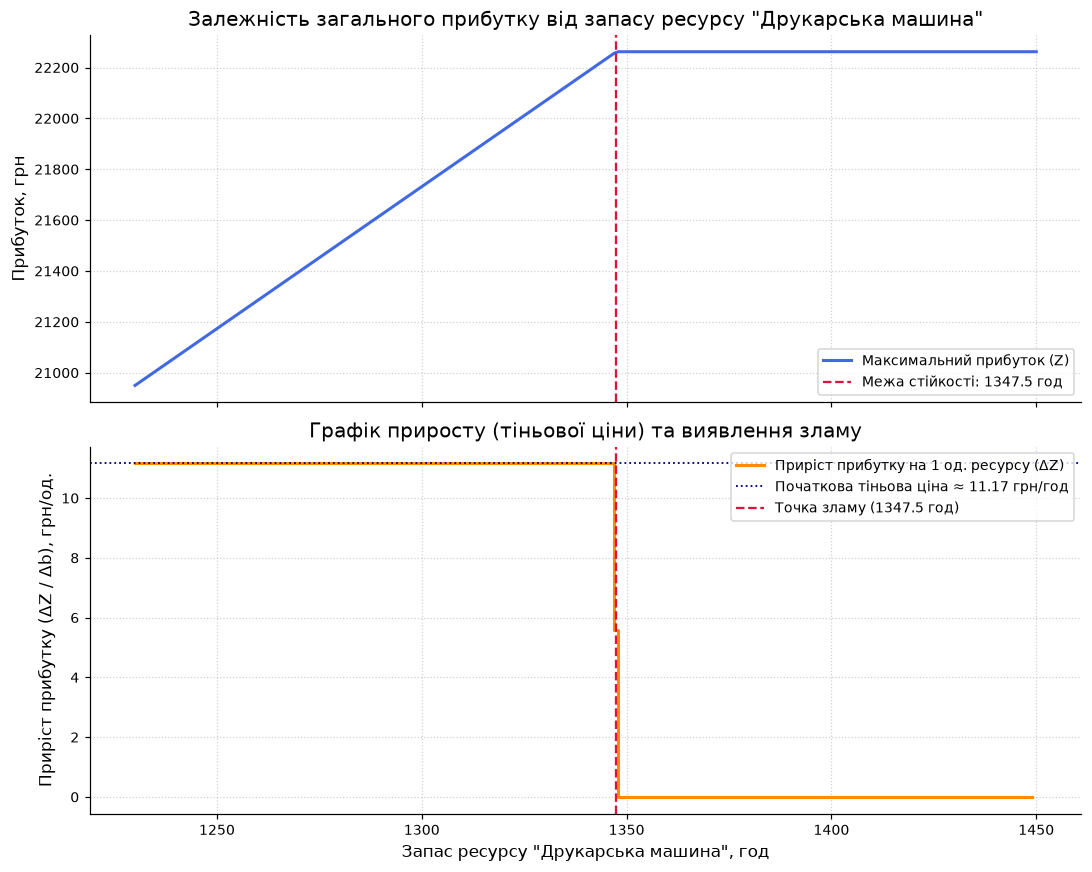

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

c = np.array([-60.0, -25.0, -59.0, -25.0])
A_ub = np.array([
    [2, 1, 3, 5],  # Крейдований папір, кг
    [3, 1, 0, 6],  # Офсетний папір, кг
    [1, 6, 1, 5],  # Фарба, кг
    [2, 2, 4, 0],  # Друкарська машина, год
    [6, 1, 2, 2]   # Різка й фальцювання, год
])

b_base = np.array([1279.0, 761.0, 376.0, 1230.0, 1065.0])
bounds = [(0, None)] * 4

capacities = np.arange(1230, 1451, 1)
profits = []

for cap in capacities:
    b_curr = b_base.copy()
    b_curr[3] = cap 
    res = linprog(c=c, A_ub=A_ub, b_ub=b_curr, bounds=bounds, method='highs')
    profits.append(-res.fun)

profits = np.array(profits)

slopes = np.diff(profits)
x_slopes = capacities[:-1] 

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Верхній графік: Загальний прибуток Z(b)
ax1.plot(capacities, profits, color='royalblue', linewidth=2, label='Максимальний прибуток (Z)')
ax1.axvline(1230 + 117.5, color='crimson', linestyle='--', linewidth=1.5, 
            label=f'Межа стійкості: {1230 + 117.5:.1f} год')
ax1.set_title('Залежність загального прибутку від запасу ресурсу "Друкарська машина"', fontsize=13)
ax1.set_ylabel('Прибуток, грн', fontsize=11)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='lower right')

# Нижній графік: Приріст прибутку / Нахил (Тіньова ціна)
ax2.step(x_slopes, slopes, where='post', color='darkorange', linewidth=2, 
         label='Приріст прибутку на 1 од. ресурсу (ΔZ)')
ax2.axhline(11.1667, color='navy', linestyle=':', linewidth=1.2, 
            label='Початкова тіньова ціна ≈ 11.17 грн/год')
ax2.axvline(1230 + 117.5, color='crimson', linestyle='--', linewidth=1.5, 
            label=f'Точка зламу ({1230 + 117.5:.1f} год)')
ax2.set_title('Графік приросту (тіньової ціни) та виявлення зламу', fontsize=13)
ax2.set_xlabel('Запас ресурсу "Друкарська машина", год', fontsize=11)
ax2.set_ylabel('Приріст прибутку (ΔZ / Δb), грн/од.', fontsize=11)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

**Відповідь 5.2:** *(на скільки одиниць можна збільшити запас, доки тіньова ціна не зміниться;
чи збігається знайдена межа з «допустимим збільшенням» зі звіту Excel)*

Можна збільшити запас на 117,5 одиниць і після цього тіньова ціна впаде. Значення збігається з допустимим збільшенням зі звіту Excel.

---
# Етап 6. Рішення про закупівлю

Постачальник пропонує вам додатковий обсяг ресурсу — див. блок «ПРОПОЗИЦІЯ
ПОСТАЧАЛЬНИКА» у ваших даних.

### Завдання 6.1
Дайте відповідь директорові на три питання, спираючись на числа, а не на здоровий глузд:

1. **Брати чи не брати?** Порівняйте ціну пропозиції з тіньовою ціною.
2. **Скільки саме брати?** Постачальник пропонує більше, ніж вам потрібно.
3. **Скільки на цьому заробимо?** Порахуйте виграш і перевірте його прямим
   розв'язанням задачі з новим запасом.

In [9]:
c = np.array([-60.0, -25.0, -59.0, -25.0])
A_ub = np.array([
    [2, 1, 3, 5],  # Крейдований папір, кг
    [3, 1, 0, 6],  # Офсетний папір, кг
    [1, 6, 1, 5],  # Фарба, кг
    [2, 2, 4, 0],  # Друкарська машина, год
    [6, 1, 2, 2]   # Різка й фальцювання, год
])

b_base = np.array([1279, 761, 376, 1347.5, 1065])

b_2 = np.array([1279, 761, 376, 1230, 1065])

bounds = [(0, None)] * 4

res_1 = linprog(
    c=c,
    A_ub=A_ub,
    b_ub=b_base,
    bounds=bounds,
    method='highs'
)

res_2 = linprog(
    c=c,
    A_ub=A_ub,
    b_ub=b_2,
    bounds=bounds,
    method='highs'
)

print('Res without additional res: ', -res_1['fun'])
print('Res with additional res: ', -res_2['fun'])
print('Diff: ', res_2['fun'] - res_1['fun'])
print('Profit: ', res_2['fun'] - res_1['fun'] - 9.5 * 117.5)

Res without additional res:  22262.25
Res with additional res:  20950.166666666664
Diff:  1312.0833333333358
Profit:  195.83333333333576


**Відповідь 6.1:**

* Брати чи ні і чому: Брати, тому що його ціна за одиницю менша за прибуток з цієї ж одиниці товару.
* Скільки одиниць має сенс купити і чому не більше: є сенс купити тільки 117.5 одиниць продукції, це зв'язано з тим що більше нам просто не треба. Кожен наступна куплена одиниця продукту не буде приносити нам прибутку, тому що будуть інші дефіцитні ресурси.
* Очікуваний виграш: 117.5 * (11.1667 - 9.5) = 117.5 * 1.6667 = 195.83грн
* Перевірка прямим розв'язанням дала: 195.83


---
# Етап 7. Перевірка розв'язку

### Завдання 7.1
Порахуйте дві величини:

* скільки виробів мають **ненульовий** випуск;
* скільки обмежень **зв'язні** (ресурс витрачено повністю).

Порівняйте.

In [10]:
# ВАШ КОД

c = np.array([-60.0, -25.0, -59.0, -25.0])

A_ub = np.array([
    [2, 1, 3, 5],  # Крейдований папір, кг
    [3, 1, 0, 6],  # Офсетний папір, кг
    [1, 6, 1, 5],  # Фарба, кг
    [2, 2, 4, 0],  # Друкарська машина, год
    [6, 1, 2, 2]   # Різка й фальцювання, год
])

b_base = np.array([1279.0, 761.0, 376.0, 1230.0, 1065.0])
bounds = [(0, None)] * 4

res = linprog(c=c, A_ub=A_ub, b_ub=b_base, bounds=bounds, method='highs')

EPS = 1e-4

nonzero_vars_mask = res.x > EPS
num_nonzero = int(np.sum(nonzero_vars_mask))

binding_constraints_mask = res.slack < EPS
num_binding = int(np.sum(binding_constraints_mask))

ненульових = num_nonzero

звязних = num_binding


In [11]:
assert ненульових is not None and звязних is not None, 'спершу порахуйте'
print('ненульових змінних: %s | зв’язних обмежень: %s' % (ненульових, звязних))
assert ненульових == звязних, ('числа не збіглися — це сигнал. Перевірте розв’язок '
                               'і поясніть причину в клітинці нижче')
print('Етап 7 пройдено')

ненульових змінних: 3 | зв’язних обмежень: 3
Етап 7 пройдено


**Відповідь 7.1:** *(чи збіглися числа; що означала б розбіжність на практиці)*

Числа збіглись. Якби вони не збіглись, це означало б, що зв'язних ресурсів більше, ніж виробів (виродженість) або що зв'язних ресурсів менше, ніж виробів (альтернативні оптимуми).

---
# Етап 8. Цілочисельність

Ваш оптимальний план містить дробові числа. Виготовити 63,3 виробу неможливо.

### Завдання 8.1
Порівняйте три варіанти:

1. розв'язок без умови цілочисельності (уже маєте);
2. **округлений** план — округліть кожне значення до цілого й перевірте, чи він
   узагалі допустимий і скільки прибутку дає;
3. справжній **цілочисельний** оптимум — розв'яжіть задачу з умовою, що всі змінні цілі
   (`cat='Integer'` у PuLP або `integrality=1` у `linprog`).

In [12]:
profit_coeff = np.array([60.0, 25.0, 59.0, 25.0])  
c = -profit_coeff 

A_ub = np.array([
    [2, 1, 3, 5],  # Крейдований папір, кг (<= 1279)
    [3, 1, 0, 6],  # Офсетний папір, кг (<= 761)
    [1, 6, 1, 5],  # Фарба, кг (<= 376)
    [2, 2, 4, 0],  # Друкарська машина, год (<= 1230)
    [6, 1, 2, 2]   # Різка й фальцювання, год (<= 1065)
])
b_ub = np.array([1279.0, 761.0, 376.0, 1230.0, 1065.0])
bounds = [(0, None)] * 4

# =====================================================================
# ВАРІАНТ 1: Розв'язок без умови цілочисельності (Неперервний LP)
# =====================================================================
res_cont = linprog(c=c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method='highs')
x_cont = res_cont.x
profit_cont = -res_cont.fun

print('Option 1:')
print('X: ', x_cont)
print('profit: ', profit_cont)

# =====================================================================
# ВАРІАНТ 2: Округлений план (np.round до найближчого цілого)
# =====================================================================
x_round = np.round(x_cont).astype(int)

# Перевірка допустимості: фактичні витрати кожного ресурсу
usage_round = A_ub @ x_round
is_feasible_round = np.all(usage_round <= b_ub)
profit_round = np.dot(profit_coeff, x_round) if is_feasible_round else "Недопустимий"

print('\nOption 2:')
print('X: ', x_round)
print('profit: ', profit_round)
print('Feasibility: ', is_feasible_round)

# =====================================================================
# ВАРІАНТ 3: Справжній цілочисельний оптимум (ILP через integrality=1)
# =====================================================================
# integrality=1 вказує для кожної змінної, що вона має бути строго цілочисельною
res_int = linprog(
    c=c, 
    A_ub=A_ub, 
    b_ub=b_ub, 
    bounds=bounds, 
    integrality=np.ones(4), 
    method='highs'
)
x_int = res_int.x.astype(int)
profit_int = -res_int.fun
usage_int = A_ub @ x_int
is_feasible_int = res_int.success

print('\nOption 3:')
print('X: ', x_int)
print('profit: ', profit_int)
print('Feasibility: ', is_feasible_int)


Option 1:
X:  [ 88.04166667   0.         263.47916667   4.89583333]
profit:  20950.166666666664

Option 2:
X:  [ 88   0 263   5]
profit:  20922.0
Feasibility:  True

Option 3:
X:  [ 88   0 263   5]
profit:  20922.0
Feasibility:  True


**Відповідь 8.1:**

| Варіант | План | Прибуток | Допустимий? |
|---|---|---|---|
| без умови цілочисельності | [ 88.04166667   0.         263.47916667   4.89583333] | 20950.16 | Так |
| округлений | [ 88   0 263   5] | 20922.0 | Так |
| цілочисельний оптимум | [ 88   0 263   5] | 20922.0 | Так |

**Висновок:** *(чи можна округлювати і чому)*
Можна округлювати, тому що у моєму конкретному варіанті математичне округлення дало допустимий план.


---
# ЧАСТИНА 2. Транспортна задача

Друга частина виконується самостійно. Тут ви застосуєте ту саму методику до задачі
іншого класу — і побачите, що вона поводиться інакше.

# Етап 9. Ваші дані

### Завдання 9.1
Сформуйте власні дані:

* **три міста-постачальники** — за першими трьома літерами вашого **прізвища**;
* **чотири міста-споживачі** — за першими чотирма літерами вашого **імені**;
* **матриця відстаней 3 × 4** — реальні відстані автошляхами за Google Maps, у кілометрах;
* **запаси і попит** — невеликі цілі числа, підберіть так, щоб **сумарний запас
  дорівнював сумарному попиту**.

> Якщо на якусь літеру міста немає — беріть наступну літеру прізвища чи імені.
> Якщо сумарний запас не дорівнює попиту, задача з обмеженнями-рівностями
> **не матиме розв'язку взагалі**. Це не помилка Python — це властивість моделі.

In [13]:
# ВАШ КОД — впишіть свої дані
постачальники = ['Красилів', 'Лиман', 'Моршин']            # напр. ['Шостка', 'Енергодар', 'Вінниця']
споживачі     = ['Дрогобич', 'Андрушівка', 'Новомиргород', 'Лозова']            # напр. ['Тернопіль', 'Афанасіївка', 'Рівне', 'Апостолове']
D = np.array( [#Дрогобич    #Андрушівка     #Новомиргород   #Лозова
              [308,        219,           462,           863    ], #Красилів
              [1314,       863,           615,           156    ], #Лиман
              [41,         530,           712,           1113    ]  #Моршин
              ])              # матриця відстаней 3 x 4, км
запас = [80, 70, 100]                    # 3 числа
попит = [65, 75, 50, 60]                    # 4 числа

assert len(постачальники) == 3 and len(споживачі) == 4, 'потрібно 3 постачальники і 4 споживачі'
assert D.shape == (3, 4), 'матриця відстаней має бути 3 x 4'
assert sum(запас) == sum(попит), 'сумарний запас має дорівнювати сумарному попиту'
pd.DataFrame(D, index=постачальники, columns=споживачі)

,Дрогобич,Андрушівка,Новомиргород,Лозова
Красилів,308,219,462,863
Лиман,1314,863,615,156
Моршин,41,530,712,1113


---
# Етап 10. Розв'язання транспортної задачі

### Завдання 10.1
Розв'яжіть задачу **двічі різними засобами**: наприклад `pulp` і
`scipy.optimize.linprog(method='highs')`. Обмеження — рівності.

Для кожного розв'язку виведіть: оптимальний план перевезень, сумарну вартість
і **тіньові ціни всіх обмежень**.

In [33]:
import numpy as np
import pandas as pd
from scipy.optimize import linprog

suppliers = ['Красилів', 'Лиман', 'Моршин']
consumers = ['Дрогобич', 'Андрушівка', 'Новомиргород', 'Лозова']

D = np.array([
    [308, 219, 462, 863],   # Красилів
    [1314, 863, 615, 156],  # Лиман
    [41, 530, 712, 1113]    # Моршин
])

supply = np.array([80, 70, 100])
demand = np.array([65, 75, 50, 60])

m, n = D.shape

print("Розв'язок за допомогою scipy")

c = D.flatten()

A_eq = []
b_eq = []

# Обмеження на запаси постачальників: sum_j x_ij = supply_i (m штук)
for i in range(m):
    row = np.zeros((m, n))
    row[i, :] = 1
    A_eq.append(row.flatten())
    b_eq.append(supply[i])


# Обмеження на попит споживачів: sum_i x_ij = demand_j (n штук)
for j in range(n):
    col = np.zeros((m, n))
    col[:, j] = 1
    A_eq.append(col.flatten())
    b_eq.append(demand[j])

A_eq = np.array(A_eq)
b_eq = np.array(b_eq)
bounds = [(0, None) for _ in range(m * n)]

res_scipy = linprog(c, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method='highs')

cost_scipy = res_scipy.fun
duals_scipy = res_scipy.eqlin.marginals

print(f"\nСумарна вартість перевезень: {cost_scipy:.2f}")

# Тіньові ціни SciPy
print("\nТіньові ціни (двоїсті оцінки / Shadow Prices) зі SciPy:")
for i, name in enumerate(suppliers):
    print(f"  * Постачальник '{name}': {duals_scipy[i]:.2f}")
for j, name in enumerate(consumers):
    print(f"  * Споживач '{name}': {duals_scipy[m + j]:.2f}")

# План перевезень
plan_scipy = pd.DataFrame(res_scipy.x.reshape(m, n), index=suppliers, columns=consumers)
display(plan_scipy.round(2))


Розв'язок за допомогою scipy

Сумарна вартість перевезень: 61830.00

Тіньові ціни (двоїсті оцінки / Shadow Prices) зі SciPy:
  * Постачальник 'Красилів': -0.00
  * Постачальник 'Лиман': 153.00
  * Постачальник 'Моршин': 250.00
  * Споживач 'Дрогобич': -209.00
  * Споживач 'Андрушівка': 219.00
  * Споживач 'Новомиргород': 462.00
  * Споживач 'Лозова': 3.00


,Дрогобич,Андрушівка,Новомиргород,Лозова
Красилів,0.0,75.0,5.0,0.0
Лиман,0.0,0.0,10.0,60.0
Моршин,65.0,0.0,35.0,0.0


In [35]:
print("Розв'язок за допомогою pulp\n")

model = pulp.LpProblem("Transportation_problem", pulp.LpMinimize)

x = pulp.LpVariable.dicts(
    "x", [(i, j) for i in range(m) for j in range(n)], lowBound=0
)

# Цільова функція
model += pulp.lpSum(D[i, j] * x[(i, j)] for i in range(m) for j in range(n))

# Обмеження за запасом
supply_constraints = []
for i in range(m):
    constraint = pulp.lpSum(x[(i, j)] for j in range(n)) == supply[i]
    model += constraint, f"supply_{i}"
    supply_constraints.append(constraint)

# Обмеження за попитом
demand_constraints = []
for j in range(n):
    constraint = pulp.lpSum(x[(i, j)] for i in range(m)) == demand[j]
    model += constraint, f"demand_{j}"
    demand_constraints.append(constraint)

model.solve(pulp.PULP_CBC_CMD(msg=False))

print("Мінімальна вартість:", pulp.value(model.objective))

# Сирі тіньові ціни
u_raw = np.array([constraint.pi for constraint in supply_constraints])
v_raw = np.array([constraint.pi for constraint in demand_constraints])

shadow_supply = pd.Series(u_raw, index=suppliers, name="shadow price (supply)")
shadow_demand = pd.Series(v_raw, index=consumers, name="shadow price (demand)")

print(shadow_supply, "\n")
print(shadow_demand, '\n')

# План перевезень
plan_pulp = pd.DataFrame([[x[(i, j)].value() for j in range(n)] for i in range(m)],
                         index=suppliers, columns=consumers)
display(plan_pulp.round(2))


Розв'язок за допомогою pulp

Мінімальна вартість: 61830.0
Красилів      3.0
Лиман       156.0
Моршин      253.0
Name: shadow price (supply), dtype: float64 

Дрогобич       -212.0
Андрушівка      216.0
Новомиргород    459.0
Лозова            0.0
Name: shadow price (demand), dtype: float64 



,Дрогобич,Андрушівка,Новомиргород,Лозова
Красилів,0.0,75.0,5.0,0.0
Лиман,0.0,0.0,10.0,60.0
Моршин,65.0,0.0,35.0,0.0


### Завдання 10.2 — головне питання цієї частини
Порівняйте два набори тіньових цін.

**Сумарна вартість у двох розв'язувачів однакова. А тіньові ціни?**

Якщо вони різні — це не помилка. Знайдіть закономірність: подивіться на різницю
між відповідними значеннями окремо для постачальників і окремо для споживачів.

In [36]:
duals_scipy = res_scipy.eqlin.marginals
duals_pulp = np.array(
    [constraint.pi for constraint in supply_constraints]
    + [constraint.pi for constraint in demand_constraints]
)

diff = duals_pulp - duals_scipy

diff_suppliers = diff[:m]
diff_consumers = diff[m:]

print("Різниця pulp - scipy")
print("Постачальники:", np.round(diff_suppliers, 6))
print("Споживачі:    ", np.round(diff_consumers, 6))


Різниця pulp - scipy
Постачальники: [3. 3. 3.]
Споживачі:     [-3. -3. -3. -3.]


**Відповідь 10.2:**

* Вартість у двох розв'язувачів: 61830.0
* Тіньові ціни збіглися чи ні: ні, якщо порівнювати значення, повернуті
  солверами (сирі). Різниця pulp - scipy: +3 для всіх постачальників і -3
  для всіх споживачів.
* Яку закономірність ви побачили в різниці: усі постачальники зсунуті на
  одну й ту саму константу t = 3, усі споживачі на -t = -3. Причина:
  задача збалансована (сума запасів = сума попиту = 250), тож одне
  обмеження лінійно залежне від решти, і двоїсті оцінки визначені з
  точністю до константи. 
* Що це означає для того, хто збирається ухвалювати рішення за цим звітом: абсолютне значення тіньової ціни окремого вузла не має однозначного
  змісту, бо залежить від зсуву, який обрав солвер.


---
# Етап 11. Перевірка розв'язку — і чому вона тут не працює

### Завдання 11.1
Порахуйте для транспортної задачі те саме, що на етапі 7:

* кількість **ненульових перевезень**;
* кількість **зв'язних обмежень**.

Порівняйте з числом `3 + 4 = 7` — кількістю обмежень у задачі.

In [37]:
tol = 1e-9

x_opt = res_scipy.x
X_opt = x_opt.reshape(m, n)

# Ненульові перевезення
nonzero_shipments = int(np.sum(x_opt > tol))

# Зв'язні обмеження
binding_eq = int(np.sum(np.abs(res_scipy.eqlin.residual) < tol))

# Зв'язні обмеження
binding_lower = int(np.sum(res_scipy.lower.residual < tol))

n_constraints = m + n   # 3 + 4 = 7

print(f"Ненульових перевезень: {nonzero_shipments}")
print(f"Зв'язних обмежень-рівностей: {binding_eq} з {n_constraints}")
print(f"Зв'язних обмежень x_ij >= 0: {binding_lower} з {m * n}")
print(f"Усього зв'язних обмежень: {binding_eq + binding_lower} (змінних: {m * n})")
print(f"Порівняння: ненульових = {nonzero_shipments}, m + n = {n_constraints}, m + n - 1 = {n_constraints - 1}")

Ненульових перевезень: 6
Зв'язних обмежень-рівностей: 7 з 7
Зв'язних обмежень x_ij >= 0: 6 з 12
Усього зв'язних обмежень: 13 (змінних: 12)
Порівняння: ненульових = 6, m + n = 7, m + n - 1 = 6


**Відповідь 11.1:**

* Ненульових перевезень: 6
* Зв'язних обмежень: 7
* Чому в транспортній задачі зв'язними виявляються **всі** обмеження:  усі обмеження транспортної задачі є рівностями, а рівність виконується як рівність у будь-якій допустимій точці, тож жодне з них не може мати "запасу"
* На скільки ненульових перевезень менше і чому саме на стільки: на одне (6 проти 7). Задача збалансована: сума запасів = сума попиту = 250,
  тож сума всіх 3 рівностей за запасом дорівнює сумі всіх 4 рівностей за
  попитом. Одне обмеження є наслідком інших, і лінійно незалежних серед
  7 обмежень лише m + n - 1 = 6.


### Завдання 11.2 — візуалізація
Побудуйте дві теплові карти поруч: матрицю відстаней і матрицю оптимальних перевезень.
Підпишіть осі та значення в комірках.

*За бажанням (не оцінюється): граф маршрутів через `networkx`, де товщина ребра
пропорційна обсягу перевезення.*

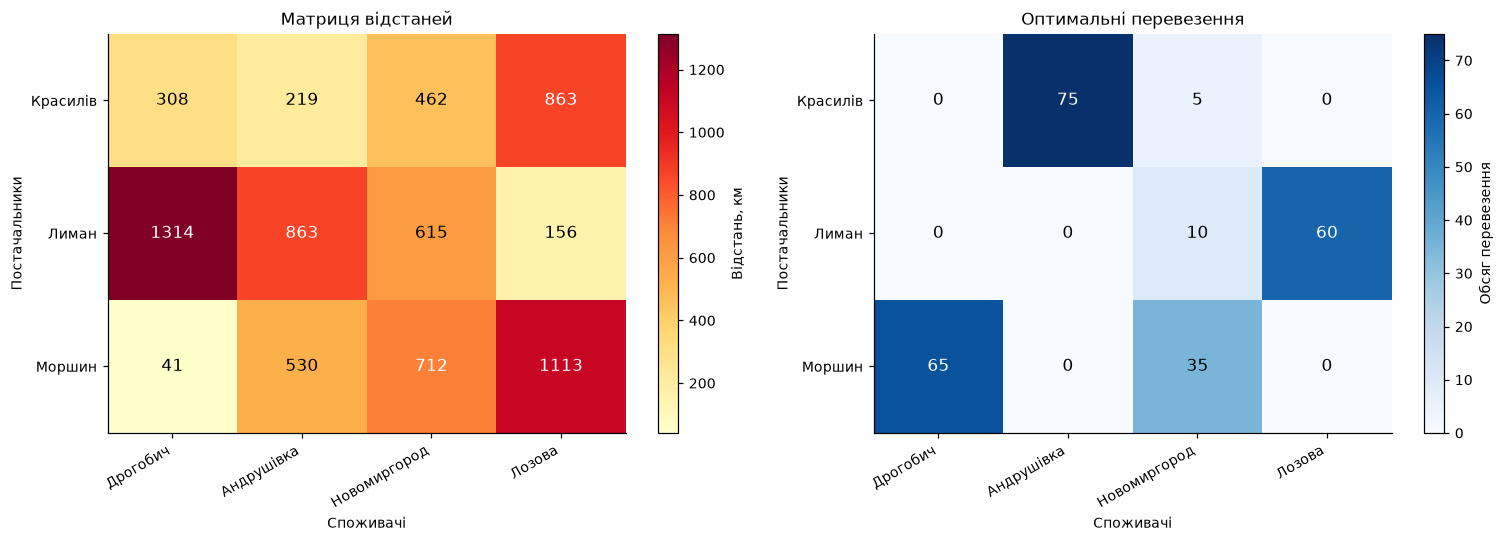

In [38]:
import numpy as np
import matplotlib.pyplot as plt

X_opt = res_scipy.x.reshape(m, n)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


def draw_heatmap(ax, matrix, title, cmap, fmt, cbar_label):
    im = ax.imshow(matrix, cmap=cmap, aspect="auto")

    ax.set_xticks(range(len(consumers)))
    ax.set_yticks(range(len(suppliers)))
    ax.set_xticklabels(consumers, rotation=30, ha="right")
    ax.set_yticklabels(suppliers)
    ax.set_xlabel("Споживачі")
    ax.set_ylabel("Постачальники")
    ax.set_title(title)

    threshold = (matrix.max() + matrix.min()) / 2
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            value = matrix[i, j]
            color = "white" if value > threshold else "black"
            ax.text(j, i, format(value, fmt),
                    ha="center", va="center", color=color, fontsize=11)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)


draw_heatmap(axes[0], D, "Матриця відстаней",
             cmap="YlOrRd", fmt=".0f", cbar_label="Відстань, км")

draw_heatmap(axes[1], np.round(X_opt, 6), "Оптимальні перевезення",
             cmap="Blues", fmt=".0f", cbar_label="Обсяг перевезення")

plt.tight_layout()
plt.show()


**Висновок:** *(одне речення про те, що видно на теплових картах)* 

Оптимальний план зосереджує перевезення на найкоротших маршрутах (світлі комірки на карті відстаней відповідають темним на карті перевезень) і повністю уникає найдовших, а віддалений Новомиргород забирає залишки запасів усіх трьох постачальників.

---
# Етап 12. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями **дозволено**. Обов'язковою є прозорість.
Порушенням є не використання інструмента, а нездатність пояснити власний код
і власні числа на захисті.

Для кожного етапу оберіть одне: `'ні'`, `'синтаксис'`, `'код, перевірено'`,
`'текст, перероблено'`, `'текст, як є'`.

In [20]:
ІНСТРУМЕНТИ_ШІ = 'Gemini'     # напр. 'ChatGPT' або 'не використовував'

ДЕКЛАРАЦІЯ = {
    'етап 1, формалізація моделі':          'ні',
    'етап 2, побудова моделі в Excel':      'синтаксис',
    'етап 3, код на Python':                'синтаксис',
    'етапи 4–5, читання та перевірка звіту': 'текст, перероблено',
    'етап 6, рішення про закупівлю':        'ні',
    'етапи 7–8, перевірка та цілочисельність': 'код, перевірено',
    'етапи 9–11, транспортна задача':       'код, перевірено',
}

# Що саме ви перевірили за згенерованим кодом чи текстом — конкретно.
ЩО_ПЕРЕВІРЕНО = 'На етапах 7-8 перевірив чи правильно пораховано кількість зв\'язних обмежень і скільки виробів мають ненульовий випуск. На етапах 9-11 перевірив точність виконання транспортної задачі і як побудовано теплову карту матриці відстаней.'

# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-яке число
# цієї роботи та внести зміни в модель на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True

In [21]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}
assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше (зараз %d символів, '
                                           'потрібно щонайменше 120)' % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'
print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-42s %s' % ('автор:', ПІБ))
print('%-42s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-42s %s' % (k + ':', v))
print('-' * 78)
print(ЩО_ПЕРЕВІРЕНО)

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                     Климишин Данило Ігорович
інструменти:                               Gemini
------------------------------------------------------------------------------
етап 1, формалізація моделі:               ні
етап 2, побудова моделі в Excel:           синтаксис
етап 3, код на Python:                     синтаксис
етапи 4–5, читання та перевірка звіту:     текст, перероблено
етап 6, рішення про закупівлю:             ні
етапи 7–8, перевірка та цілочисельність:   код, перевірено
етапи 9–11, транспортна задача:            код, перевірено
------------------------------------------------------------------------------
На етапах 7-8 перевірив чи правильно пораховано кількість зв'язних обмежень і скільки виробів мають ненульовий випуск. На етапах 9-11 перевірив точність виконання транспортної задачі і як побудовано теплову карту матриці відстаней.


---
# Крок 13. Фінальна самоперевірка

In [22]:
перевірки = {
    'ПІБ і варіант заповнено':            bool(ПІБ) and 1 <= ВАРІАНТ <= 30,
    'Excel і Python дали однаковий план': abs(прибуток - EXCEL_ПРИБУТОК) < 0.5,
    'перевірку «ненульові = зв’язні» зроблено': ненульових == звязних,
    'дані транспортної задачі введено':   len(постачальники) == 3 and len(споживачі) == 4,
    'баланс запасів і попиту':            sum(запас) == sum(попит),
    'декларацію заповнено':               bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)
if all(перевірки.values()):
    print('\nТехнічна частина виконана.')
    print('Переконайтеся, що заповнені ВСІ клітинки з відповідями,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     Excel і Python дали однаковий план
OK     перевірку «ненульові = зв’язні» зроблено
OK     дані транспортної задачі введено
OK     баланс запасів і попиту
OK     декларацію заповнено

Технічна частина виконана.
Переконайтеся, що заповнені ВСІ клітинки з відповідями,
і виконайте Kernel → Restart & Run All перед здачею.
